In [72]:
# Imports
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import re
from scipy.stats import mannwhitneyu 

## 1. Inventario

In [15]:
DATA = Path("C:\Python\Proyectos_GitHub\PSIB2026Q2-TPI-Grupo07-Barboza-Casais-Mitchelena\data\multiple-sclerosis\MS")
CARPETAS = {
    "Control Axial_crop":    ("Control", "Axial"),
    "Control Saggital_crop": ("Control", "Sagital"),
    "MS Axial_crop":         ("MS", "Axial"),
    "MS Saggital_crop":      ("MS", "Sagital"),
}

filas = [{"ruta": p, "Clase": c, "Corte": k, "ext": p.suffix.lower()}
         for carpeta, (c, k) in CARPETAS.items()
         for p in sorted((DATA / carpeta).iterdir())]
df = pd.DataFrame(filas)

print(df.groupby(["Clase", "Corte"]).size().unstack())
print("\nTotal de fotos:", len(df))
print("Extensión de los datos: ")
df["ext"].value_counts().to_frame()

Corte    Axial  Sagital
Clase                  
Control   1002     1014
MS         650      761

Total de fotos: 3427
Extensión de los datos: 


,count
ext,
.png,3427


&nbsp; Las fotos tienen todas extensión .png, un método de compresión sin périda por lo que no vamos a tener problema con artefactos de compresión previos. El dataset contiene resonáncias (MRI) en FLAIR en dos cortes: axial y sagital. Además, los datos se dividen en dos grupos:

* Control: sujetos sanos, 59 pacientes. 
* MS: sujetos con esclerosis múltiple, 72 pacientes.

## 2. Resolución, modo y tamaño

In [29]:
def props(p):
    with Image.open(p) as im:
        return pd.Series({"ancho": im.size[0], "alto": im.size[1], "modo": im.mode})

df[["ancho", "alto", "modo"]] = df["ruta"].apply(props)
df["kb"] = df["ruta"].apply(lambda p: p.stat().st_size / 1024)
tabla = df["modo"].value_counts().rename_axis("Modo de color").reset_index(name="Cantidad")
print(tabla.to_string(index=False), " \n")
print("\n----------------------------")
print(" --- Tamaño de las fotos ---")
print("----------------------------")

resumen = df.groupby(["Clase", "Corte"])[["ancho", "alto"]].agg(["min", "median", "max"])
resumen.columns = ["Ancho mín", "Ancho mediana", "Ancho máx", "Alto mín", "Alto mediana", "Alto máx"]
display(resumen)
print(f"Peso total: {df['kb'].sum()/1024:.1f} MB")

Modo de color  Cantidad
          RGB      3427  


----------------------------
 --- Tamaño de las fotos ---
----------------------------


Ancho mín  Ancho mediana  Ancho máx  Alto mín  Alto mediana  \
Clase   Corte                                                                  
Control Axial          286          443.5        629       297         481.5   
        Sagital        276          566.0        639       314         541.0   
MS      Axial          290          426.0        611       262         484.0   
        Sagital        327          531.0        899       276         560.0   

                 Alto máx  
Clase   Corte              
Control Axial         628  
        Sagital       628  
MS      Axial         695  
        Sagital       719

Peso total: 425.1 MB


## 3. Visulización de ejemplos

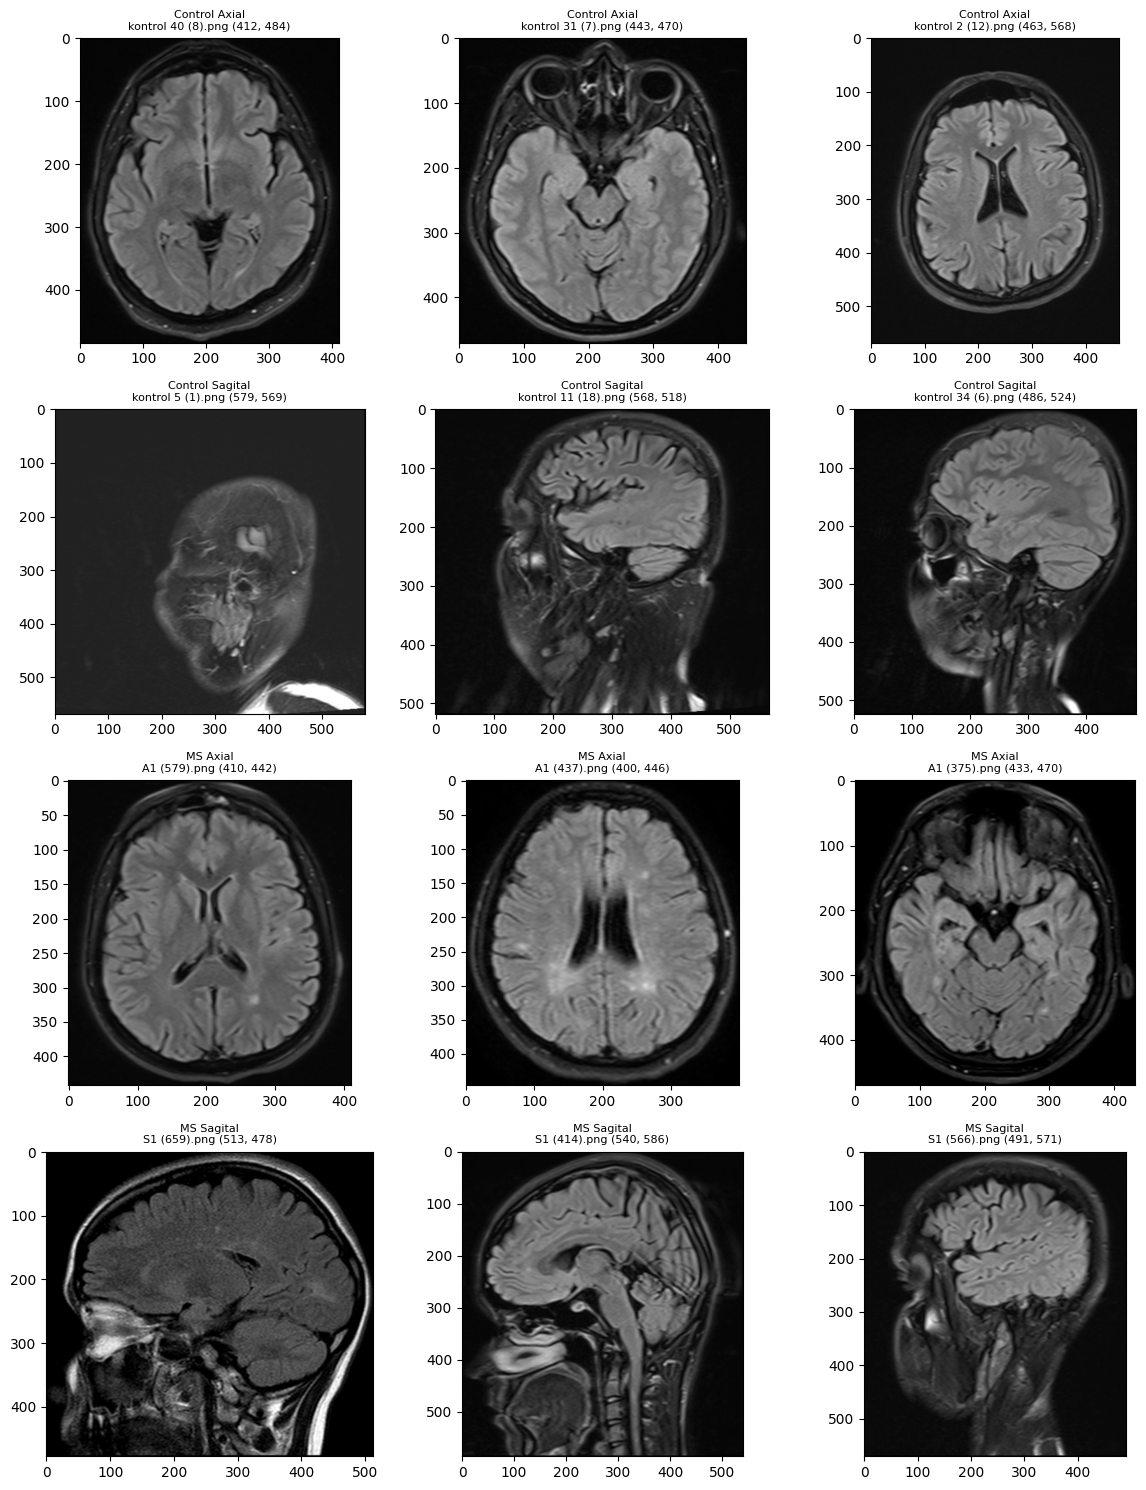

In [31]:
grupos = list(df.groupby(["Clase", "Corte"]))
fig, axs = plt.subplots(4, 3, figsize=(12, 15))
for fila, ((clase, corte), g) in zip(axs, grupos):
    for ax, (_, r) in zip(fila, g.sample(3, random_state=0).iterrows()):
        im = Image.open(r["ruta"])
        ax.imshow(im, cmap="gray")
        ax.set_title(f"{clase} {corte}\n{r['ruta'].name} {im.size}", fontsize=8)
plt.tight_layout()
plt.show()

# 4. Estructura del dataset: cuántos pacientes hay y en qué cortes.

In [56]:
patron = re.compile(r"(\d*)\s*[a-zA-Z]?\s*\((\d+)\)\s*$")
m = df["ruta"].apply(lambda p: patron.search(p.stem))

print("\n//////////////////////////////////")
print("Etiquetado de los datos de control")
print("//////////////////////////////////")
df["IdNombre"] = m.apply(lambda x: x.group(1) if x and x.group(1) else None)
df.loc[df["Clase"] == "MS", "IdNombre"] = None   # en MS "1" de A1/S1 es fijo, no es un ID

ctrl = df[df["Clase"] == "Control"]
display(ctrl.groupby("Corte").agg(
    Archivos=("ruta", "size"),
    Con_ID=("IdNombre", lambda s: s.notna().sum()),
    Sin_ID=("IdNombre", lambda s: s.isna().sum()),
    Pacientes=("IdNombre", "nunique")))

def tramos(g):
    cambio = (g[["ancho", "alto"]] != g[["ancho", "alto"]].shift()).any(axis=1)
    return cambio.cumsum()

print("\n||||||||||||||||||||||||||||||||||||||||||||||||")
print("Varianción del tamaño de las imágenes en control")
print("||||||||||||||||||||||||||||||||||||||||||||||||")
filas = []
for corte, g in df[(df["Clase"] == "Control") & df["IdNombre"].notna()].groupby("Corte"):
    g = g.assign(Id=g["IdNombre"].astype(int)).sort_values(["Id", "N"])
    g["Tramo"] = tramos(g)
    un_tamano = (g.groupby("Id")[["ancho", "alto"]].nunique().max(axis=1) == 1).mean() * 100
    filas.append({"Corte": corte, "Pacientes reales": g["Id"].nunique(),
                  "Tramos por tamaño": g["Tramo"].nunique(),
                  "% pacientes con un solo tamaño": round(un_tamano, 1)})
display(pd.DataFrame(filas))

print("\n******************************")
print("Comparación entre control y MS")
print("******************************")

resumen = df.groupby(["Clase", "Corte"]).agg(
    Archivos=("ruta", "size"),
    N_min=("N", "min"), N_max=("N", "max"), N_unicos=("N", "nunique"),
    Con_ID=("IdNombre", lambda s: s.notna().sum()),
    Pacientes_por_nombre=("IdNombre", "nunique"))
display(resumen)
print("Sujetos según el paper: MS = 72, Control = 59")


//////////////////////////////////
Etiquetado de los datos de control
//////////////////////////////////


,Archivos,Con_ID,Sin_ID,Pacientes
Corte,,,,
Axial,1002,853,149,48
Sagital,1014,1014,0,48



||||||||||||||||||||||||||||||||||||||||||||||||
Varianción del tamaño de las imágenes en control
||||||||||||||||||||||||||||||||||||||||||||||||


,Corte,Pacientes reales,Tramos por tamaño,% pacientes con un solo tamaño
0,Axial,48,602,4.2
1,Sagital,48,690,0.0



******************************
Comparación entre control y MS
******************************


Archivos  N_min  N_max  N_unicos  Con_ID  \
Clase   Corte                                               
Control Axial        1002      1     92        92     853   
        Sagital      1014      1     24        24    1014   
MS      Axial         650      1    650       650       0   
        Sagital       761      1    761       761       0   

                 Pacientes_por_nombre  
Clase   Corte                          
Control Axial                      48  
        Sagital                    48  
MS      Axial                       0  
        Sagital                     0

Sujetos según el paper: MS = 72, Control = 59



&ensp; Cada archivo es un corte, no un paciente. Los 3427 archivos pertenecen a 131 sujetos (72 MS y 59 controles) y cada sujeto aporta una pila de cortes que recorre la cabeza.

- **Control:** el nombre trae el ID de paciente (`kontrol 17 (1)`: paciente 17, corte 1).
- **MS:** el nombre es `A1 (n)` / `S1 (n)`, con un contador continuo que mezcla a todos los pacientes. No trae ID.

&ensp; Lo que hicimos fue: 

1. Extraer el ID de paciente y el número de corte de los nombres de Control.
2. Poner a prueba un criterio para reconstruir pacientes en MS: que el tamaño del recorte sea constante dentro de un paciente, de modo que los saltos de tamaño marquen el cambio de paciente. Lo validamos en Control, donde conocemos los IDs.

**Resultado.** El criterio **no se sostiene**: solo el 4,2 % de los pacientes de Control en axial (0 % en sagital) tiene todos sus cortes con el mismo tamaño. Cada corte está recortado individualmente alrededor del cerebro, y el tamaño cambia a lo largo de la pila. Por lo tanto **no se puede reconstruir el ID de paciente en MS** a partir del tamaño de la imagen.

**Limitación a declarar.** En MS no hay ID de paciente, así que no es posible una partición por paciente. La comparación estadística entre grupos trata cada corte como una observación, aunque cortes del mismo paciente no son independientes.

**Observación.** Control tiene en promedio más cortes por paciente que MS, tanto axiales como sagitales.

**IDs de Control.** En axial se identifican 48 pacientes (IDs 1 a 48). Los otros 149 cortes forman dos secuencias de numeración continua sin ID: `kontrol (1..92)` y `kontrol aks (1..57)`, cada una mezcla a un número desconocido de pacientes, igual que MS. En sagital hay 48 pacientes identificados (IDs 1 a 49, sin el 48), con nombres `kontrol 35 s (n)`. El paper reporta 59 controles, así que no todos quedan identificados por nombre.

# 5. Visualización de histogramas

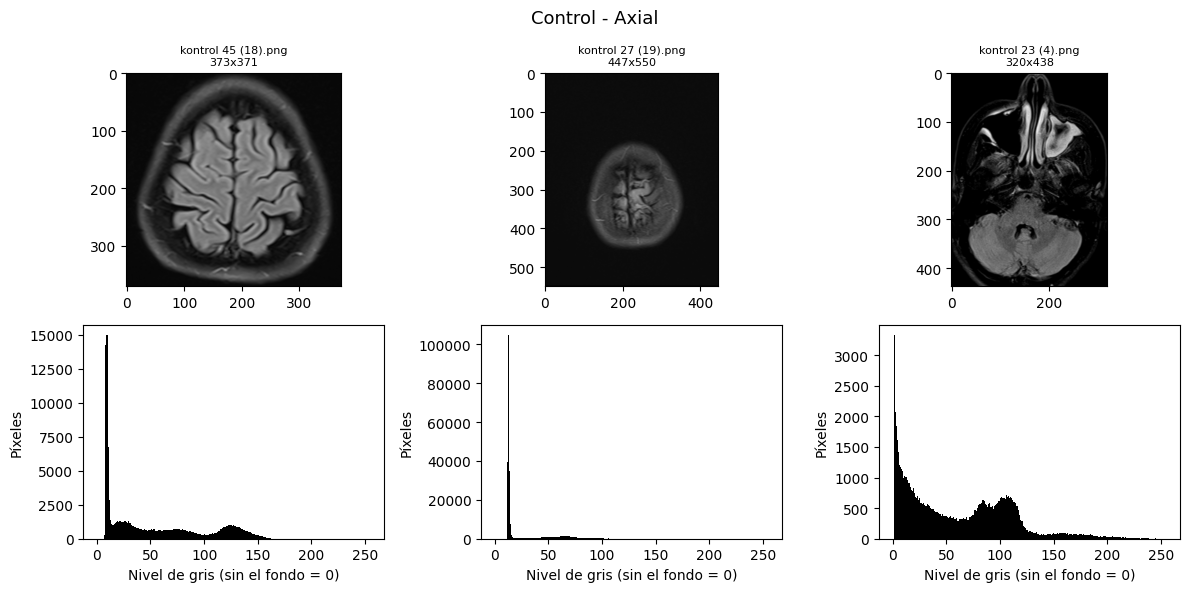

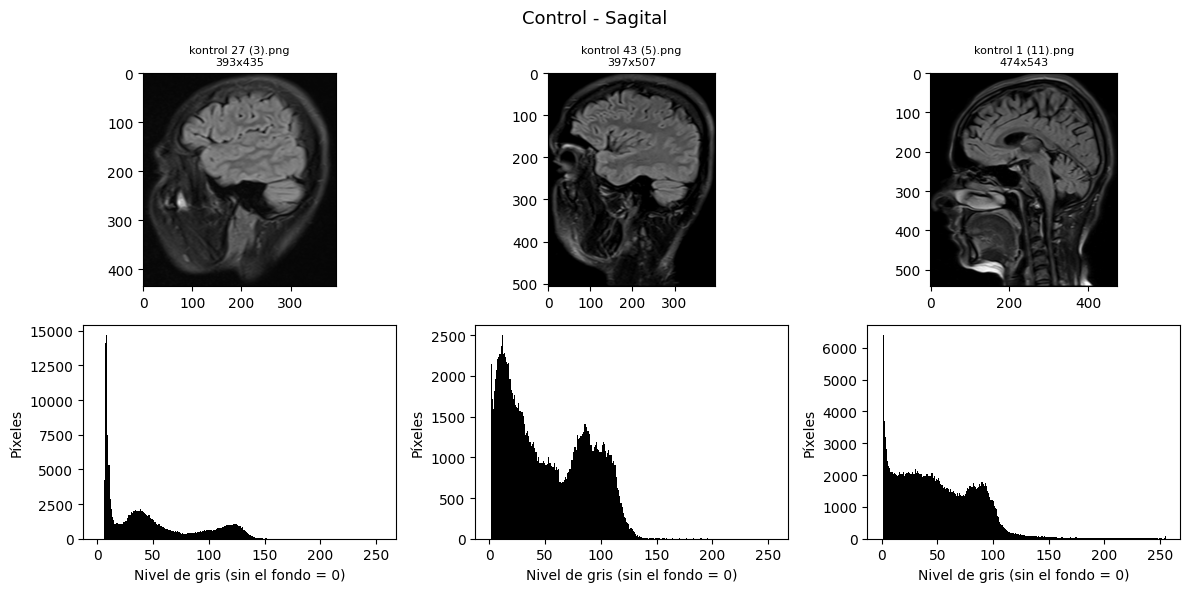

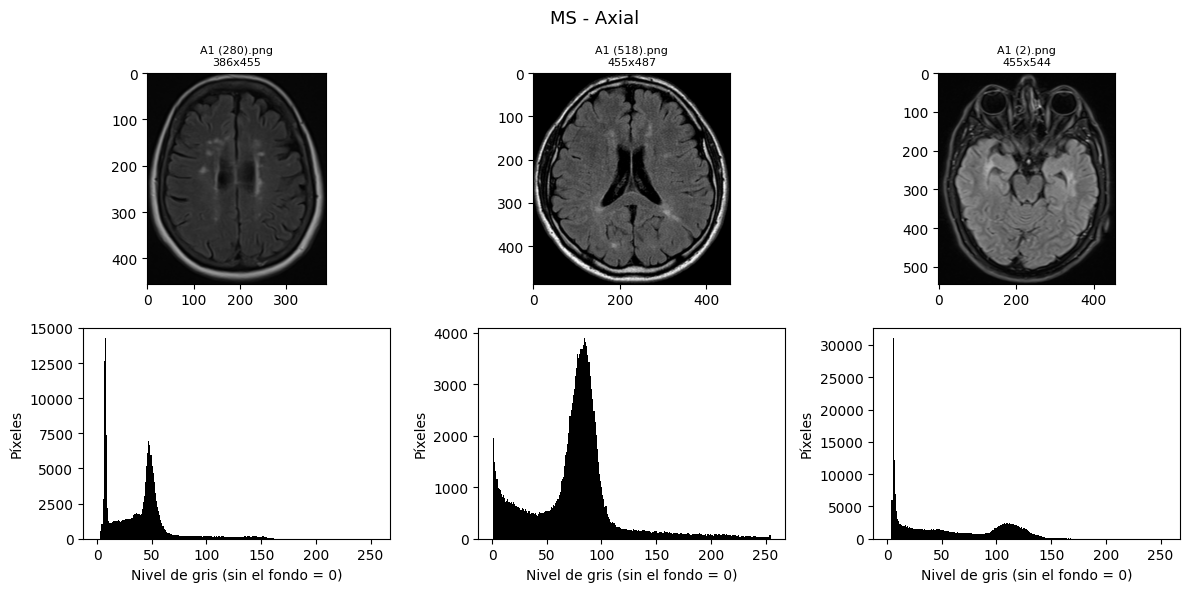

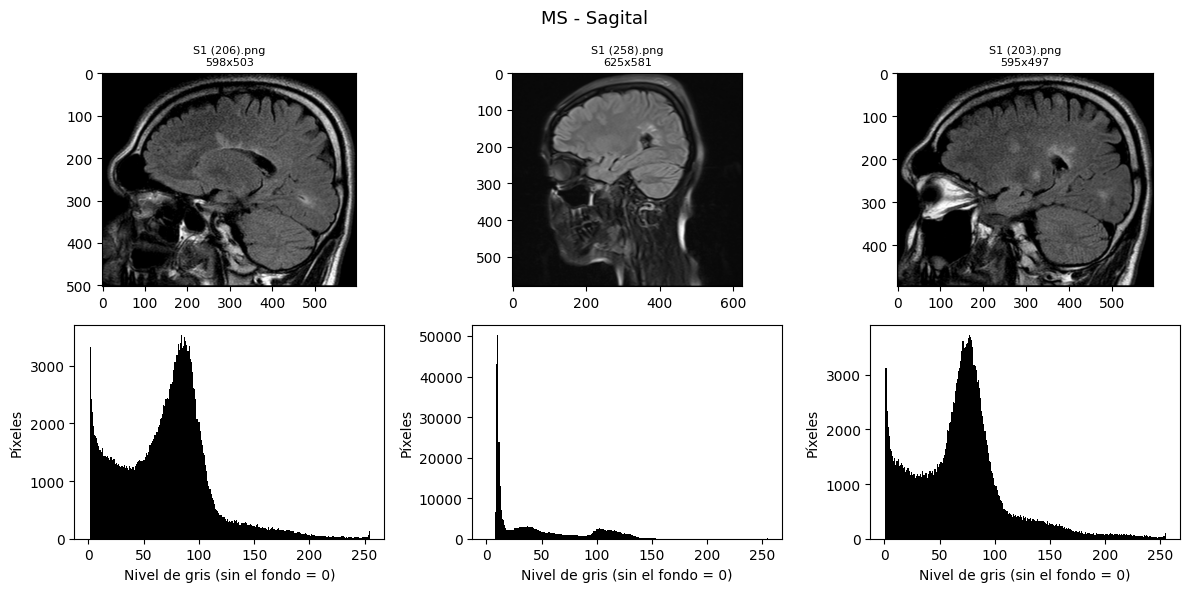

In [66]:
# Algunas imágenes al azar
def a_gris(ruta):
    return np.asarray(Image.open(ruta).convert("L"))

N = 3
for (clase, corte), g in df.groupby(["Clase", "Corte"]):
    muestra = g.sample(N)
    fig, axs = plt.subplots(2, N, figsize=(12, 6))
    for j, (_, r) in enumerate(muestra.iterrows()):
        img = a_gris(r["ruta"])
        axs[0, j].imshow(img, cmap="gray", vmin=0, vmax=255)
        axs[0, j].set_title(f"{r['ruta'].name}\n{img.shape[1]}x{img.shape[0]}", fontsize=8)
        axs[1, j].hist(img[img > 0].ravel(), bins=256, range=(0, 255), color="k")
        axs[1, j].set_xlabel("Nivel de gris (sin el fondo = 0)")
        axs[1, j].set_ylabel("Píxeles")
    fig.suptitle(f"{clase} - {corte}", fontsize=13)
    plt.tight_layout()
    plt.show()

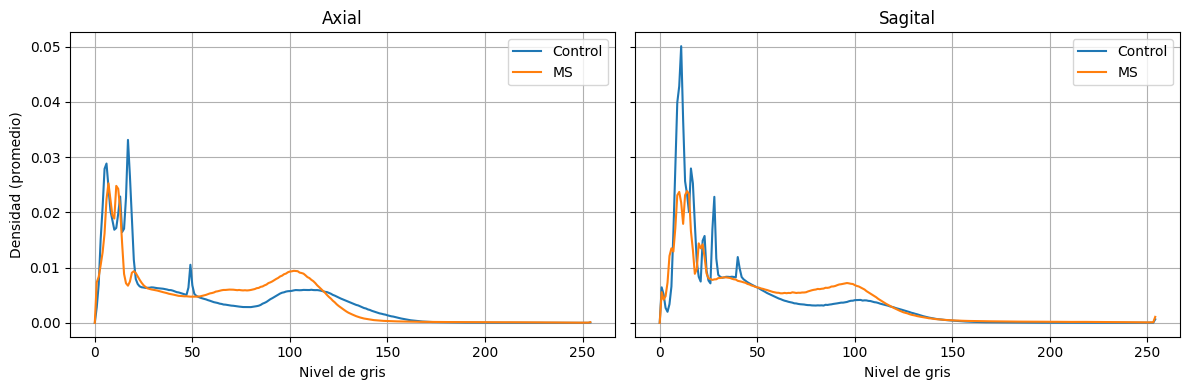

In [ ]:
# Promediamos 100 histogramas al azar
bins = np.linspace(0, 255, 256)
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
plt.grid()
for ax, corte in zip(axs, ["Axial", "Sagital"]):
    for clase in ["Control", "MS"]:
        g = df[(df["Clase"] == clase) & (df["Corte"] == corte)].sample(100)
        hs = []
        for ruta in g["ruta"]:
            v = a_gris(ruta)
            hs.append(np.histogram(v[v > 0], bins=bins, density=True)[0])
        ax.plot(bins[:-1], np.mean(hs, axis=0), label=clase)
    ax.set_title(corte); ax.set_xlabel("Nivel de gris"); ax.legend()
axs[0].set_ylabel("Densidad (promedio)")
axs[0].set_ticks(np.arange(0, 256, 50))
plt.tight_layout()
for ax in axs:
    ax.grid(True)
plt.show()

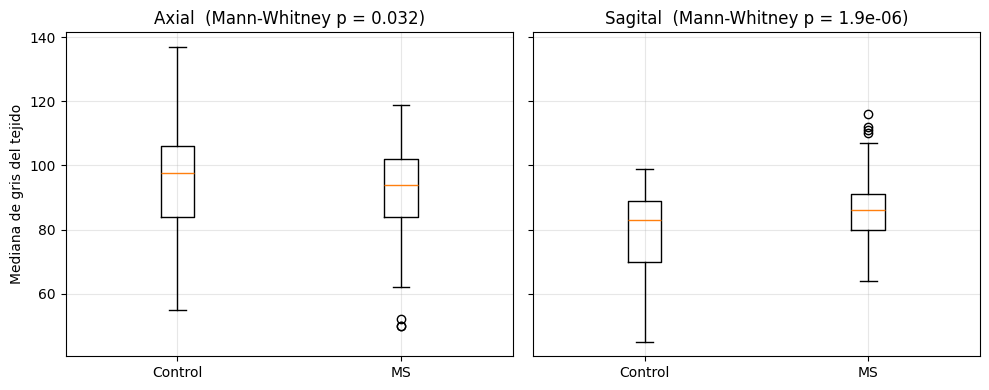

count  mean  median   std
Clase   Corte                             
Control Axial      200  95.5    97.5  16.7
        Sagital    200  79.3    83.0  11.9
MS      Axial      200  91.4    94.0  14.4
        Sagital    200  85.6    86.0   8.6

In [ ]:
# Boxplots de la distribución de niveles de gris
UMBRAL = 40   # por encima se considera "tejido" (el pico oscuro llega a ~30). 

def mediana_tejido(ruta):
    v = a_gris(ruta)
    v = v[v > UMBRAL]
    return np.median(v) if v.size else np.nan

muestra = df.groupby(["Clase", "Corte"]).sample(n=200)   # 200 al azar por grupo
muestra["Mediana"] = muestra["ruta"].apply(mediana_tejido)

print("\n==================================================")
print("Estadísticos de la distribución de niveles de gris")
print("==================================================")
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, corte in zip(axs, ["Axial", "Sagital"]):
    d = [muestra[(muestra["Clase"] == c) & (muestra["Corte"] == corte)]["Mediana"].dropna()
         for c in ["Control", "MS"]]
    ax.boxplot(d, tick_labels=["Control", "MS"])
    ax.set_title(f"{corte}  (Mann-Whitney p = {mannwhitneyu(*d).pvalue:.2g})")
    ax.grid(True, alpha=0.3)
axs[0].set_ylabel("Mediana de gris del tejido")
plt.tight_layout()
plt.show()

display(muestra.groupby(["Clase", "Corte"])["Mediana"].agg(["count", "mean", "median", "std"]).round(1))